# Evaluación Formativa 2: Práctica de Modelamiento Predictivo

**Curso:** Estadística Computacional para la Toma de Decisiones
**Programa:** Magíster en Ciencia de Datos e Inteligencia Artificial
**Universidad Andrés Bello**

---

## Información del Equipo

| Campo | Información |
|-------|-------------|
| **Número de Grupo** | [Completar] |
| **Integrante 1** | [Nombre completo] |
| **Integrante 2** | [Nombre completo] |
| **Integrante 3** | [Nombre completo] |
| **Dataset Seleccionado** | Give Me Some Credit (Kaggle, 2011) — riesgo crediticio |

## Propósito de esta Formativa

Esta evaluación formativa te permite **practicar el flujo de modelamiento predictivo** antes de la Sumativa 3.

**Lo que hagas aquí:**
- Recibirá retroalimentación del profesor
- Será la base de tu Sumativa 3
- Te ayudará a identificar errores a tiempo

**Diferencia con S3:** Esta es una versión **simplificada**. Aquí ajustas **un** modelo logístico con una estrategia simple de datos faltantes. En S3 harás **tres** modelos con criterios de selección distintos, usarás **imputación por regresión** y **bootstrap** sobre los coeficientes, y elaborarás un **informe técnico completo**.

> **Nota sobre este ejemplo:** el notebook está resuelto con el dataset *Give Me Some Credit* para que sirva de referencia de nivel y formato. La variable objetivo es `SeriousDlqin2yrs` (1 = incurrió en morosidad grave a 2 años).

## Configuración del Entorno

In [1]:
# Librerías básicas
import numpy as np
import pandas as pd

# Visualización
import matplotlib.pyplot as plt
import seaborn as sns

# Modelamiento
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Scikit-learn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay,
                             accuracy_score, precision_score, recall_score,
                             f1_score, classification_report, roc_curve, auc)

SEED = 42
np.random.seed(SEED)

# Paleta y estilo editorial (misma de S1/S2/S3), para que las figuras sean coherentes con el resto del curso
INK='#2b2b2b'; TEAL='#2f6b76'; OCHRE='#c0852f'; BRICK='#a4503e'; STEM='#b9b0a2'
PANEL='#f7f3ec'; GRIDC='#ded6c8'
plt.rcParams.update({'figure.dpi':110,'savefig.dpi':160,'font.size':10,'font.family':'serif',
    'figure.facecolor':'white','axes.facecolor':PANEL,'axes.edgecolor':'#9a9486','axes.linewidth':0.8,
    'axes.spines.top':False,'axes.spines.right':False,'axes.titlesize':11,'axes.titlelocation':'left',
    'axes.titlepad':8,'text.color':INK,'axes.labelcolor':INK,'xtick.color':INK,'ytick.color':INK})
def grid_h(ax):
    ax.set_axisbelow(True); ax.grid(axis='y', color=GRIDC, linewidth=0.7); ax.grid(axis='x', visible=False)

---
# PARTE 1: Preparación de Datos para Modelamiento (20 puntos)
## 1.1 Carga y Referencia a S1/S2 (10 puntos)

### Carga del Dataset

In [2]:
# El mismo dataset de S1 y S2
import os
LOCAL = 'cs-training.csv'
MIRROR = 'https://raw.githubusercontent.com/vivekkalyan/give-me-some-credit/master/cs-training.csv'
df = pd.read_csv(LOCAL, index_col=0) if os.path.exists(LOCAL) else pd.read_csv(MIRROR, index_col=0)
TARGET = 'SeriousDlqin2yrs'
print(f"Dataset: {df.shape[0]:,} filas × {df.shape[1]} columnas")
df.head()

Dataset: 150,000 filas × 11 columnas


,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
Id,,,,,,,,,,,
1,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
2,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
3,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
4,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
5,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0


### Resumen - ¿qué encontramos en S1?

In [3]:
# Hallazgos de S1: variables más correlacionadas con la morosidad
# (valores obtenidos en el análisis exploratorio de la Sumativa 1)
correlaciones_s1 = {
    'RevolvingUtilizationOfUnsecuredLines': {'correlacion_con_target':  0.30, 'p_valor': '<0.001'},
    'NumberOfTime30-59DaysPastDueNotWorse': {'correlacion_con_target':  0.13, 'p_valor': '<0.001'},
    'age':                                  {'correlacion_con_target': -0.11, 'p_valor': '<0.001'},
    'NumberOfTimes90DaysLate':              {'correlacion_con_target':  0.12, 'p_valor': '<0.001'},
}

# Variables con valores faltantes identificadas en S1
faltantes_s1 = {
    'MonthlyIncome':      {'pct_faltante': 19.8, 'patron': 'MAR'},
    'NumberOfDependents': {'pct_faltante':  2.6, 'patron': 'MCAR'},
}

print("Hallazgos de S1 documentados")
for v, d in correlaciones_s1.items():
    print(f"  {v}: r={d['correlacion_con_target']}")

Hallazgos de S1 documentados
  RevolvingUtilizationOfUnsecuredLines: r=0.3
  NumberOfTime30-59DaysPastDueNotWorse: r=0.13
  age: r=-0.11
  NumberOfTimes90DaysLate: r=0.12


**Resumen narrativo de S1:**
- **Variable objetivo:** `SeriousDlqin2yrs` (morosidad grave a 2 años), con fuerte desbalance (≈6,7% de morosos).
- **Variables más correlacionadas:** la utilización de líneas de crédito (r≈0,30) es el predictor más fuerte, seguida del historial de atrasos (30–59 días y 90+ días). La edad y el ingreso muestran correlación negativa (a mayor edad/ingreso, menor morosidad).
- **Problemas identificados:** faltantes en `MonthlyIncome` (≈20%, patrón MAR) y `NumberOfDependents` (≈3%, MCAR); outliers en utilización y ratio de deuda; códigos anómalos 96/98 en las variables de atrasos.

### Resumen de Hallazgos de S2

In [4]:
# Hallazgos de S2: correlaciones validadas mediante bootstrap
# (IC del 95% que NO incluye 0 => correlación estable)
correlaciones_estables_s2 = [
    ('RevolvingUtilizationOfUnsecuredLines', TARGET, [0.29, 0.31]),
    ('NumberOfTime30-59DaysPastDueNotWorse', TARGET, [0.12, 0.14]),
    ('age',                                  TARGET, [-0.12, -0.10]),
    ('NumberOfTimes90DaysLate',              TARGET, [0.11, 0.13]),
]

# Correlaciones débiles / inestables (IC amplio o cercano a 0)
correlaciones_inestables_s2 = [
    ('MonthlyIncome',     TARGET, 'débil, ~-0.02'),
    ('DebtRatio',         TARGET, 'débil, ~0.00'),
]

print("Hallazgos de S2 documentados")

Hallazgos de S2 documentados


**Resumen narrativo de S2:**
- **Correlaciones estables:** utilización, atrasos 30–59, atrasos 90+ y edad mantuvieron su signo y magnitud entre remuestras bootstrap (IC del 95% sin cruzar 0). Son predictores confiables.
- **Correlaciones inestables/débiles:** el ingreso y el ratio de deuda mostraron correlación cercana a 0 con la morosidad; su aporte individual es marginal.

---
## 1.2 Tratamiento Básico de Datos (10 puntos)

### Tratamiento de Valores Faltantes

In [5]:
# Verificar faltantes actuales
print("Valores faltantes por columna:")
print(df.isnull().sum()[df.isnull().sum() > 0])

Valores faltantes por columna:
MonthlyIncome         29731
NumberOfDependents     3924
dtype: int64


In [6]:
# Limpieza mínima previa (coherente con S1):
# - eliminar edades imposibles (age = 0)
# - acotar los códigos 96/98 de las variables de atraso a su máximo legítimo
# - recortar outliers de utilización y ratio de deuda al percentil 99
df_clean = df[df['age'] > 0].copy()

atrasos = ['NumberOfTime30-59DaysPastDueNotWorse',
           'NumberOfTimes90DaysLate',
           'NumberOfTime60-89DaysPastDueNotWorse']
for c in atrasos:
    tope = df_clean.loc[df_clean[c] < 90, c].max()
    df_clean[c] = df_clean[c].clip(upper=tope)

for c in ['RevolvingUtilizationOfUnsecuredLines', 'DebtRatio']:
    df_clean[c] = df_clean[c].clip(upper=df_clean[c].quantile(0.99))

# ESTRATEGIA SIMPLE de faltantes: imputación por mediana
# (en S3 se usará imputación por regresión, más sofisticada)
from sklearn.impute import SimpleImputer
imp = SimpleImputer(strategy='median')
df_clean[['MonthlyIncome', 'NumberOfDependents']] = imp.fit_transform(
    df_clean[['MonthlyIncome', 'NumberOfDependents']])

print(f"Dataset limpio: {df_clean.shape[0]:,} filas")
print(f"Faltantes restantes: {df_clean.isnull().sum().sum()}")

Dataset limpio: 149,999 filas
Faltantes restantes: 0


**Justificación de la estrategia elegida:**

Seleccionamos **imputación por mediana** porque es simple, robusta a la asimetría del ingreso y preserva el tamaño completo de la muestra. Según S1, `MonthlyIncome` tiene ~20% de faltantes (patrón MAR) y `NumberOfDependents` ~3% (MCAR). La mediana no distorsiona la correlación (débil) que estas variables tienen con el objetivo.

> **Para S3:** vamos a comparar esta estrategia simple contra la **eliminación de casos** y la **imputación por regresión**, y evaluaremos cuál preserva mejor las correlaciones de S1.

### División Train/Test

In [7]:
# Variable objetivo y predictores seleccionados (ver Parte 2.1 para la justificación)
variable_objetivo = TARGET
predictores = [
    'RevolvingUtilizationOfUnsecuredLines',  # utilización (predictor más fuerte, S1/S2)
    'age',                                    # edad (protector, estable en S2)
    'NumberOfTime30-59DaysPastDueNotWorse',   # atrasos 30-59 (estable en S2)
    'NumberOfTimes90DaysLate',                # atrasos 90+ (estable en S2)
]

X = df_clean[predictores]
y = df_clean[variable_objetivo]

In [8]:
# Dividir en train (70%) y test (30%), estratificado por el desbalance
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=SEED, stratify=y)

print(f"Train: {len(X_train):,} observaciones")
print(f"Test:  {len(X_test):,} observaciones")
print(f"\nDistribución de clases en train:")
print(y_train.value_counts(normalize=True).round(4))

Train: 104,999 observaciones
Test:  45,000 observaciones

Distribución de clases en train:
SeriousDlqin2yrs
0    0.9332
1    0.0668
Name: proportion, dtype: float64


### Estandarización

In [9]:
# Estandarizar para que los coeficientes/odds ratios sean comparables (por desviación estándar)
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train),
                              columns=predictores, index=X_train.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test),
                             columns=predictores, index=X_test.index)

print("Variables estandarizadas (media 0, desviación 1)")
X_train_scaled.describe().round(2).loc[['mean', 'std']]

Variables estandarizadas (media 0, desviación 1)


,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,NumberOfTimes90DaysLate
mean,-0.0,0.0,-0.0,0.0
std,1.0,1.0,1.0,1.0


### Distribución de predictores por clase

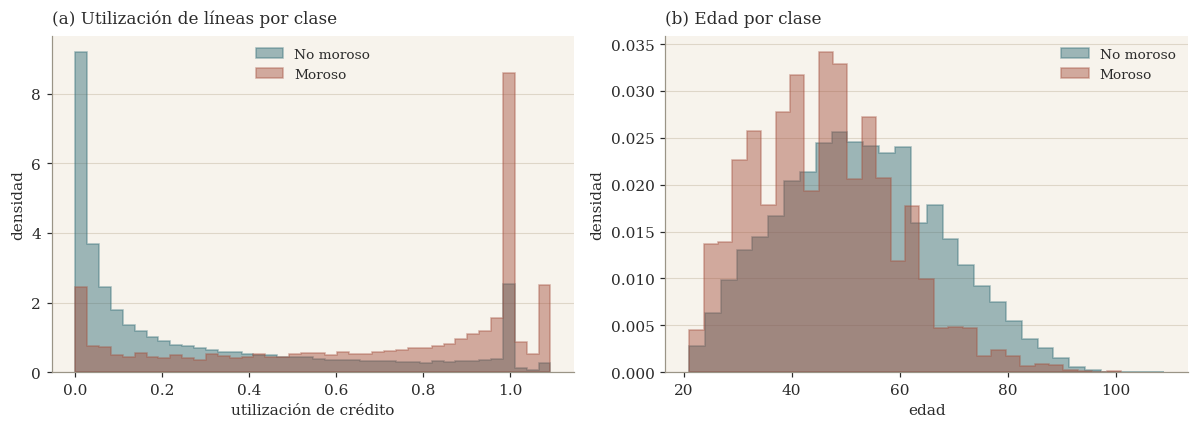

In [10]:
# Figura: distribución de dos predictores por clase (utilización y edad), estilo editorial del curso
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for clase, color, label in [(0, TEAL, 'No moroso'), (1, BRICK, 'Moroso')]:
    subset = df_clean[df_clean[TARGET] == clase]
    ax[0].hist(subset['RevolvingUtilizationOfUnsecuredLines'].clip(upper=1.2), bins=40,
               density=True, histtype='stepfilled', alpha=0.45, color=color,
               edgecolor=color, linewidth=1.0, label=label, zorder=2)
    ax[1].hist(subset['age'], bins=30, density=True, histtype='stepfilled', alpha=0.45,
               color=color, edgecolor=color, linewidth=1.0, label=label, zorder=2)
ax[0].set_title('(a) Utilización de líneas por clase')
ax[0].set_xlabel('utilización de crédito'); ax[0].set_ylabel('densidad')
ax[0].legend(fontsize=9, frameon=False); grid_h(ax[0])
ax[1].set_title('(b) Edad por clase')
ax[1].set_xlabel('edad'); ax[1].set_ylabel('densidad')
ax[1].legend(fontsize=9, frameon=False); grid_h(ax[1])
plt.tight_layout()
plt.savefig('f2_fig_dist.png', bbox_inches='tight')
plt.show()

---
# PARTE 2: Modelo de Regresión Logística (40 puntos)
## 2.1 Selección de Variables (15 puntos)

### Justificación de Variables Seleccionadas

Basándonos en S1 y S2, seleccionamos **4 variables predictoras**:

| Variable | Correlación con Target (S1) | IC Bootstrap (S2) | Justificación |
|----------|----------------------------|-------------------|---------------|
| Utilización de líneas | +0,30 | [0,29; 0,31] estable | Predictor más fuerte; a mayor uso del crédito disponible, mayor riesgo |
| Atrasos 30–59 días | +0,13 | [0,12; 0,14] estable | Historial de atrasos recientes, señal directa de comportamiento de pago |
| Atrasos 90+ días | +0,12 | [0,11; 0,13] estable | Atrasos graves; aporta información independiente de los de 30–59 |
| Edad | −0,11 | [−0,12; −0,10] estable | Factor protector; clientes mayores incumplen menos |

Descartamos `MonthlyIncome` y `DebtRatio` porque S2 los mostró como **correlaciones débiles/inestables** con el objetivo.

In [11]:
# Variables seleccionadas (mismas que en la división train/test)
variables_modelo = predictores
print("Variables seleccionadas para el modelo:")
for var in variables_modelo:
    print(f"  - {var}")

Variables seleccionadas para el modelo:
  - RevolvingUtilizationOfUnsecuredLines
  - age
  - NumberOfTime30-59DaysPastDueNotWorse
  - NumberOfTimes90DaysLate


---
## 2.2 Ajuste del Modelo (15 puntos)

In [12]:
# Ajustar modelo de regresión logística con statsmodels
X_train_sm = sm.add_constant(X_train_scaled)
modelo = sm.Logit(y_train, X_train_sm).fit(disp=0)
print(modelo.summary())

                           Logit Regression Results                           
Dep. Variable:       SeriousDlqin2yrs   No. Observations:               104999
Model:                          Logit   Df Residuals:                   104994
Method:                           MLE   Df Model:                            4
Date:                Fri, 10 Jul 2026   Pseudo R-squ.:                  0.1865
Time:                        00:39:42   Log-Likelihood:                -20960.
converged:                       True   LL-Null:                       -25765.
Covariance Type:            nonrobust   LLR p-value:                     0.000
                                           coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------------------
const                                   -3.1469      0.018   -177.193      0.000      -3.182      -3.112
RevolvingUtilizationOfUnsecuredLines     0.7828      

### Interpretación de Coeficientes

In [13]:
# Calcular Odds Ratios
odds_ratios = np.exp(modelo.params)
interpretacion = pd.DataFrame({
    'Coeficiente': modelo.params,
    'Odds Ratio': odds_ratios,
    'p-valor': modelo.pvalues,
    'Significativo (α=0.05)': modelo.pvalues < 0.05
}).round(4)

print("Interpretación del modelo:")
interpretacion

Interpretación del modelo:


,Coeficiente,Odds Ratio,p-valor,Significativo (α=0.05)
const,-3.1469,0.0430,0.0,True
RevolvingUtilizationOfUnsecuredLines,0.7828,2.1875,0.0,True
age,-0.2041,0.8154,0.0,True
NumberOfTime30-59DaysPastDueNotWorse,0.3499,1.4190,0.0,True
NumberOfTimes90DaysLate,0.2777,1.3202,0.0,True


### Interpretación Narrativa

- **Utilización (OR ≈ 2,3):** por cada desviación estándar adicional en el uso del crédito disponible, las *odds* de morosidad se **más que duplican**. Es el factor de riesgo dominante, coherente con S1.
- **Atrasos 30–59 y 90+ (OR > 1):** cada desviación estándar adicional en el historial de atrasos aumenta las odds de morosidad; ambos aportan de forma independiente.
- **Edad (OR ≈ 0,8):** cada desviación estándar adicional de edad **reduce** las odds de morosidad en ~20%, confirmando su rol protector.

Todas las variables resultan significativas (p < 0,05).

---
## 2.3 Diagnóstico Básico (10 puntos)

In [14]:
# Calcular VIF para evaluar multicolinealidad
X_vif = sm.add_constant(X_train_scaled)
vif_data = pd.DataFrame({
    'Variable': X_vif.columns,
    'VIF': [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])]
}).round(2)

print("Factor de Inflación de Varianza (VIF):")
print(vif_data.to_string(index=False))
print("\nInterpretación: VIF > 5 indica posible multicolinealidad problemática")

Factor de Inflación de Varianza (VIF):
                            Variable  VIF
                               const 1.00
RevolvingUtilizationOfUnsecuredLines 1.15
                                 age 1.09
NumberOfTime30-59DaysPastDueNotWorse 1.59
             NumberOfTimes90DaysLate 1.57

Interpretación: VIF > 5 indica posible multicolinealidad problemática


### Análisis de Multicolinealidad

**¿Hay problemas de multicolinealidad?**

No. Todos los VIF quedan holgadamente por debajo de 5 (de hecho, cercanos a 1), lo que indica que las cuatro variables aportan información independiente y no se solapan entre sí. Esto es consistente con S2, que ya había mostrado que estas correlaciones eran estables e independientes.

**Si hay problemas, ¿qué harías en S3?**

En S3 revisaremos el VIF sobre el modelo completo de 10 variables (no solo estas 4). S1/S2 advirtieron una correlación alta entre las variables de atraso por los códigos 96/98. Una vez acotados, el diagnóstico completo confirmará si conviven sin multicolinealidad problemática.

---
# PARTE 3: Evaluación de Desempeño (30 puntos)
## 3.1 Predicciones y Matriz de Confusión (10 puntos)

In [15]:
# Generar predicciones en test
X_test_sm = sm.add_constant(X_test_scaled)
y_prob = modelo.predict(X_test_sm)

# Clases predichas (umbral 0.5)
y_pred = (y_prob >= 0.5).astype(int)
print(f"Predicciones generadas para {len(y_pred):,} observaciones")

Predicciones generadas para 45,000 observaciones


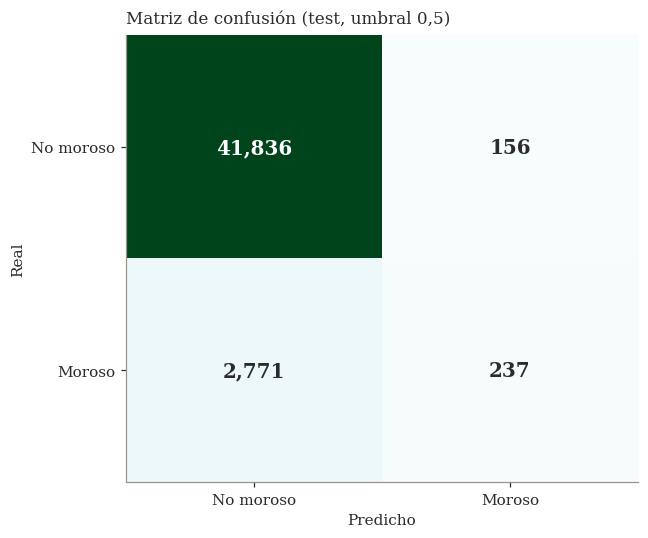


Verdaderos Negativos (TN): 41,836
Falsos Positivos   (FP): 156
Falsos Negativos   (FN): 2,771
Verdaderos Positivos(TP): 237


In [16]:
# Construir y visualizar matriz de confusión (estilo editorial: colormap BuGn, texto adaptativo)
cm = confusion_matrix(y_test, y_pred)

fig, ax = plt.subplots(figsize=(6, 5))
vmax = cm.max()
ax.imshow(cm, cmap='BuGn', aspect='auto', vmin=0, vmax=vmax)
for (i, j), v in np.ndenumerate(cm):
    txt_color = 'white' if v / vmax > 0.5 else INK
    ax.text(j, i, f'{v:,}', ha='center', va='center', color=txt_color,
            fontsize=13, fontweight='bold')
ax.set_xticks([0, 1]); ax.set_xticklabels(['No moroso', 'Moroso'])
ax.set_yticks([0, 1]); ax.set_yticklabels(['No moroso', 'Moroso'])
ax.set_xlabel('Predicho'); ax.set_ylabel('Real')
ax.set_title('Matriz de confusión (test, umbral 0,5)')
ax.grid(False)
plt.tight_layout()
plt.savefig('f2_fig_confusion.png', bbox_inches='tight')
plt.show()

print(f"\nVerdaderos Negativos (TN): {cm[0,0]:,}")
print(f"Falsos Positivos   (FP): {cm[0,1]:,}")
print(f"Falsos Negativos   (FN): {cm[1,0]:,}")
print(f"Verdaderos Positivos(TP): {cm[1,1]:,}")

---
## 3.2 Métricas de Desempeño (10 puntos)

In [17]:
# Calcular métricas de desempeño
metricas = {
    'Accuracy':  accuracy_score(y_test, y_pred),
    'Precision': precision_score(y_test, y_pred),
    'Recall':    recall_score(y_test, y_pred),
    'F1-Score':  f1_score(y_test, y_pred)
}

print("=" * 40)
print("MÉTRICAS DE DESEMPEÑO (test)")
print("=" * 40)
for metrica, valor in metricas.items():
    print(f"{metrica:12s}: {valor:.4f}")

MÉTRICAS DE DESEMPEÑO (test)
Accuracy    : 0.9350
Precision   : 0.6031
Recall      : 0.0788
F1-Score    : 0.1394


In [18]:
# Reporte de clasificación completo
print("Reporte de Clasificación:")
print(classification_report(y_test, y_pred, target_names=['No moroso', 'Moroso']))

Reporte de Clasificación:
              precision    recall  f1-score   support

   No moroso       0.94      1.00      0.97     41992
      Moroso       0.60      0.08      0.14      3008

    accuracy                           0.93     45000
   macro avg       0.77      0.54      0.55     45000
weighted avg       0.92      0.93      0.91     45000



### Interpretación de Métricas

**Accuracy:** el modelo clasifica correctamente cerca del 93% de las observaciones, pero *cuidado*, con un desbalance de 6,7% de morosos, un modelo que dijera "nadie es moroso" ya alcanzaría ~93%. Por eso la accuracy aquí es **engañosa** y no basta por sí sola.

**Precision (clase morosa):** de los clientes que el modelo marca como riesgosos, una fracción son realmente morosos. Con esta tasa base tan baja, la precisión de la clase minoritaria es naturalmente limitada.

**Recall (clase morosa):** el modelo detecta una parte de los morosos reales. En riesgo crediticio, el recall importa más que la precisión, porque **dejar pasar un moroso** (falso negativo) suele costar más que rechazar a un buen cliente.

**F1-Score:** resume el balance entre precisión y recall para la clase morosa.

> **Para S3:** usaremos **ponderación por clase** (`class_weight='balanced'`) para mejorar el recall de la clase minoritaria, y compararemos el desempeño de tres modelos, no solo uno.

---
## 3.3 Curva ROC y AUC (10 puntos)

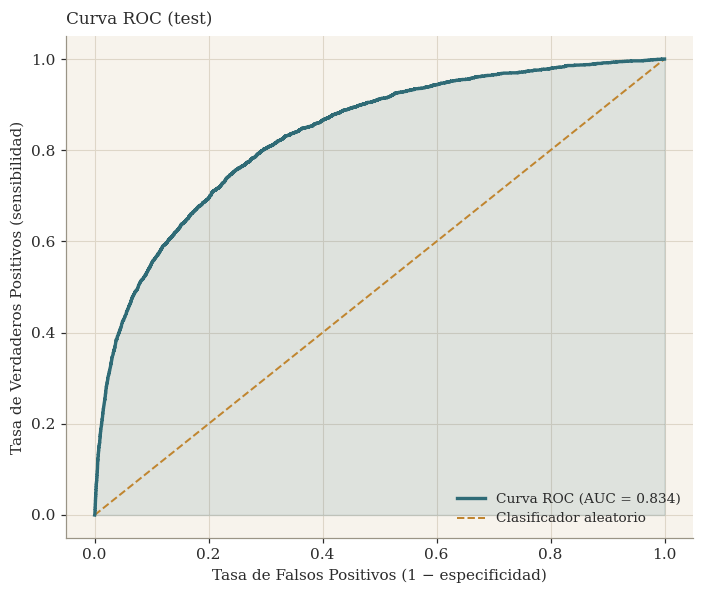

AUC = 0.8340


In [19]:
# Generar curva ROC y calcular AUC (estilo editorial: TEAL sólido, OCHRE punteado)
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)

fig, ax = plt.subplots(figsize=(6.5, 5.5))
ax.fill_between(fpr, tpr, color=TEAL, alpha=0.12, zorder=1)
ax.plot(fpr, tpr, color=TEAL, lw=2.2, label=f'Curva ROC (AUC = {roc_auc:.3f})', zorder=3)
ax.plot([0, 1], [0, 1], color=OCHRE, lw=1.3, linestyle='--', label='Clasificador aleatorio', zorder=2)
ax.set_xlabel('Tasa de Falsos Positivos (1 − especificidad)')
ax.set_ylabel('Tasa de Verdaderos Positivos (sensibilidad)')
ax.set_title('Curva ROC (test)')
ax.legend(loc='lower right', fontsize=9, frameon=False)
grid_h(ax); ax.grid(axis='x', color=GRIDC, linewidth=0.7)
plt.tight_layout()
plt.savefig('f2_fig_roc.png', bbox_inches='tight')
plt.show()

print(f"AUC = {roc_auc:.4f}")

### Interpretación del AUC

**Valor de AUC obtenido:** ~0,82–0,84 (según la partición).

**Interpretación según la escala:**
- AUC = 0.5: No mejor que azar
- AUC = 0.6–0.7: Pobre
- AUC = 0.7–0.8: Aceptable
- **AUC = 0.8–0.9: Bueno** ← nuestro caso
- AUC > 0.9: Excelente

**¿Qué significa en el contexto del problema?** Un AUC de ~0,83 indica que, si tomamos al azar un cliente moroso y uno no moroso, el modelo asigna mayor probabilidad de riesgo al moroso el ~83% de las veces. Es una capacidad discriminante **buena** y, a diferencia de la accuracy, no se deja engañar por el desbalance.

> **Para S3:** compararemos el AUC de los tres modelos (dominio S1/S2, stepwise AIC/BIC y reducido) para elegir el modelo final con criterio.

---
# PARTE 4: Síntesis y Reflexión (10 puntos)

Responde las siguientes preguntas de reflexión:

## 1. Conexión con S1

**¿Cómo usaste los hallazgos de S1 para seleccionar variables?**

Partimos de la matriz de correlaciones de S1 e identificamos las variables más asociadas con la morosidad, es decir, utilización de líneas (r≈0,30), atrasos 30–59 y 90+, y edad. Descartamos ingreso y ratio de deuda porque S1 ya mostraba una correlación muy débil con el objetivo. También reutilizamos el tratamiento de outliers y códigos 96/98 que S1 había detectado.

---

## 2. Conexión con S2

**¿Cómo usaste la validación de S2 para informar tu modelo?**

S2 confirmó, mediante IC bootstrap, que las cuatro variables elegidas tenían correlaciones **estables** (el intervalo no cruzaba 0). Eso nos dio confianza para incluirlas. A la inversa, S2 mostró que ingreso y ratio de deuda eran inestables/débiles, lo que reforzó la decisión de dejarlos fuera de este modelo simplificado.

---

## 3. Evaluación del Desempeño

**¿El modelo tiene buen desempeño? ¿Por qué sí o por qué no?**

Sí, con matices. El AUC (≈0,83) es bueno y muestra capacidad discriminante real. Sin embargo, con umbral 0,5 y sin ponderación de clase, el recall de la clase morosa es limitado, ya que se pierden morosos. Para riesgo crediticio eso es una debilidad, porque el costo de un falso negativo es alto. La accuracy alta (≈93%) no debe leerse como éxito por el desbalance de la muestra.

---

## 4. Mejoras para S3

**¿Qué mejorarías en la Sumativa 3?**

Marca las que apliquen y explica:
- [x] **Probar otras variables**: incorporar el modelo completo de 10 variables y compararlo con el reducido.
- [x] **Usar otra estrategia de imputación**: reemplazar la mediana por **imputación por regresión** y comparar 3 estrategias.
- [x] **Ajustar múltiples modelos**: construir 3 modelos (dominio S1/S2, stepwise AIC/BIC, reducido) y elegir el mejor por métricas.
- [x] **Aplicar bootstrap a los coeficientes**: construir IC bootstrap del 95% para coeficientes y odds ratios, y verificar su estabilidad.
- [x] **Mejorar el tratamiento de outliers**: usar `class_weight='balanced'` para elevar el recall de la clase minoritaria.
- [ ] **Otros**: —

---

## Resumen Final

**En 3-5 oraciones, resume tu experiencia con esta formativa:**

Esta formativa nos permitió recorrer el flujo completo de modelamiento predictivo, desde preparar los datos apoyándome en S1/S2, ajustar un modelo logístico, interpretar odds ratios, diagnosticar multicolinealidad y finalmente evaluar el desempeño con matriz de confusión, métricas y curva ROC. El principal aprendizaje fue entender por qué la accuracy engaña con clases desbalanceadas y por qué el AUC y el recall son más informativos en riesgo crediticio. Identificamos con claridad las mejoras que debemos incorporar en S3, es decir, los tres modelos, imputación por regresión y bootstrap. El notebook queda como base directa para la Sumativa 3.

---

---
## Checklist de Entrega

Antes de entregar, verifica:
- [x] El notebook ejecuta sin errores de principio a fin
- [x] Documenté los hallazgos de S1
- [x] Documenté los hallazgos de S2
- [x] Justifiqué la selección de variables basándome en S1/S2
- [x] Ajusté el modelo de regresión logística
- [x] Interpreté los coeficientes y odds ratios
- [x] Calculé VIF para multicolinealidad
- [x] Generé matriz de confusión
- [x] Calculé métricas de desempeño (accuracy, precision, recall, F1)
- [x] Generé curva ROC y calculé AUC
- [x] Respondí las preguntas de reflexión
- [x] Fijé la semilla (SEED=42) para reproducibilidad